In [191]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.preprocessing import LabelEncoder

In [192]:
df = pd.read_csv('/content/ifood_df.csv')
df.head()

,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,...,marital_Together,marital_Widow,education_2n Cycle,education_Basic,education_Graduation,education_Master,education_PhD,MntTotal,MntRegularProds,AcceptedCmpOverall
0,58138.0,0,0,58,635,88,546,172,88,88,...,0,0,0,0,1,0,0,1529,1441,0
1,46344.0,1,1,38,11,1,6,2,1,6,...,0,0,0,0,1,0,0,21,15,0
2,71613.0,0,0,26,426,49,127,111,21,42,...,1,0,0,0,1,0,0,734,692,0
3,26646.0,1,0,26,11,4,20,10,3,5,...,1,0,0,0,1,0,0,48,43,0
4,58293.0,1,0,94,173,43,118,46,27,15,...,0,0,0,0,0,0,1,407,392,0


In [193]:
df.tail()

,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,...,marital_Together,marital_Widow,education_2n Cycle,education_Basic,education_Graduation,education_Master,education_PhD,MntTotal,MntRegularProds,AcceptedCmpOverall
2200,61223.0,0,1,46,709,43,182,42,118,247,...,0,0,0,0,1,0,0,1094,847,0
2201,64014.0,2,1,56,406,0,30,0,0,8,...,1,0,0,0,0,0,1,436,428,1
2202,56981.0,0,0,91,908,48,217,32,12,24,...,0,0,0,0,1,0,0,1217,1193,1
2203,69245.0,0,1,8,428,30,214,80,30,61,...,1,0,0,0,0,1,0,782,721,0
2204,52869.0,1,1,40,84,3,61,2,1,21,...,0,0,0,0,0,0,1,151,130,0


In [194]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2205 entries, 0 to 2204
Data columns (total 39 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Income                2205 non-null   float64
 1   Kidhome               2205 non-null   int64  
 2   Teenhome              2205 non-null   int64  
 3   Recency               2205 non-null   int64  
 4   MntWines              2205 non-null   int64  
 5   MntFruits             2205 non-null   int64  
 6   MntMeatProducts       2205 non-null   int64  
 7   MntFishProducts       2205 non-null   int64  
 8   MntSweetProducts      2205 non-null   int64  
 9   MntGoldProds          2205 non-null   int64  
 10  NumDealsPurchases     2205 non-null   int64  
 11  NumWebPurchases       2205 non-null   int64  
 12  NumCatalogPurchases   2205 non-null   int64  
 13  NumStorePurchases     2205 non-null   int64  
 14  NumWebVisitsMonth     2205 non-null   int64  
 15  AcceptedCmp3         

In [195]:
df.shape

(2205, 39)

In [196]:
df.columns

Index(['Income', 'Kidhome', 'Teenhome', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response',
       'Age', 'Customer_Days', 'marital_Divorced', 'marital_Married',
       'marital_Single', 'marital_Together', 'marital_Widow',
       'education_2n Cycle', 'education_Basic', 'education_Graduation',
       'education_Master', 'education_PhD', 'MntTotal', 'MntRegularProds',
       'AcceptedCmpOverall'],
      dtype='object')

In [197]:
df.isnull().sum()

,0
Income,0
Kidhome,0
Teenhome,0
Recency,0
MntWines,0
MntFruits,0
MntMeatProducts,0
MntFishProducts,0
MntSweetProducts,0
MntGoldProds,0


In [198]:
df['Age'].nunique()

56

In [199]:
df['Age'].unique()

array([63, 66, 55, 36, 39, 53, 49, 35, 46, 70, 44, 61, 68, 33, 74, 40, 71,
       38, 41, 69, 51, 31, 57, 50, 47, 77, 45, 24, 52, 56, 43, 42, 65, 54,
       32, 72, 62, 48, 60, 37, 75, 29, 58, 67, 64, 28, 59, 34, 30, 73, 27,
       26, 79, 76, 25, 80])

In [200]:
df['AcceptedCmpOverall'].nunique()

5

In [201]:
df['AcceptedCmpOverall'].unique()

array([0, 1, 2, 3, 4])

In [202]:
df['MntRegularProds'].nunique()

974

In [203]:
df['MntRegularProds'].unique()

array([1441,   15,  692,   43,  392,  688,  536,  123,   42,   23,   29,
       1042,  282,   36, 1225,   88,  261, 1430,   55,  220, 1728,  934,
        534,  246,   49,  175,  111, 1672,   22,  140,  114,  216, 1152,
         59,  843,    9,  818, 1191,   39,   16,    7,  636, 1243,  479,
       1629,   66, 1135,  388, 1577, 1013,   19,  432, 1278,  600,  546,
        594, 1016,    4,   11, 1198,  435, 1416, 1229,  691,  623,   47,
       1854, 2107,    0,  590,  131,    8,   33,  626,   50,  141,  304,
       1076,  180,   24,   27,  456,  532,   52,   45,  947,  958, 1021,
        173,  780,   91,  764,  811, 1648,  488,  686,  407,   60, 1658,
        337,   21,  564,  799,  215, 1491,   82,  637,  347,  550,  465,
        233, 1482,   74,   30, 2037,  953, 1133,  805,   80,  779,   14,
        147,  433,  434,  247,  869, 1297,  300,   18,  134, 1117,    3,
       1640, 1269,   32,  367,  255,   25,   94,   81, 1783, 1096,   41,
        177,  751,   35,  374, 1551, 1078,  291,   

In [204]:
df['MntTotal'].nunique()

897

In [205]:
df['MntTotal'].unique()

array([1529,   21,  734,   48,  407,  702,  563,  146,   44,   36,   45,
       1072,  296,   41, 1270,   92,  289, 1606,   94,  268, 1729,  953,
        539,  345,   62,  216,  121, 1672,   26,  229,  117,  259, 1174,
        878,   63,  860, 1293,   46,   19,  810,   72,   42, 1281,  493,
       1661,   69, 1376,  497, 1767, 1053,   24,  475, 1358,  606,  715,
        600, 1046,   11, 1236,  544, 1489, 1241,  777,  642,   56,   12,
       1872, 2158,    9,  641,  148,   53,  338, 1221,  187,   28,   43,
        531,   61,  755,  399,   50, 1058, 1039, 1059,   20,  180,  845,
        118,  807,  890, 1734,  548,  708,  479,   87, 1691,  457,   51,
         30,  612,   70,   23,  967,  387, 1707,   86,  649,  405,  591,
        595,  256, 1482,   90,   29,   34, 2057, 1003, 1259,  838,  196,
        828,   52,   18,  179,  119,  446,  447,  945, 1339,  303,    8,
       1673,  116,   60,  394,  257,  993,   71, 1809, 1207,  184,  892,
         54,   33,   37,  491, 1566,   64, 1180,  8

In [206]:
df['education_PhD'].nunique()

2

In [207]:
df['education_PhD'].unique()

array([0, 1])

In [208]:
df['education_Master'].nunique()

2

In [209]:
df['education_Master'].unique()

array([0, 1])

In [210]:
df['education_Graduation'].nunique()

2

In [211]:
df['education_Graduation'].unique()

array([1, 0])

In [212]:
df['education_Basic'].nunique()

2

In [213]:
df['education_Basic'].unique()

array([0, 1])

In [214]:
df['Income'].nunique()

1963

In [215]:
df['Income'].unique()

array([58138., 46344., 71613., ..., 56981., 69245., 52869.], shape=(1963,))

In [216]:
df['Kidhome'].nunique()

3

In [217]:
df['Kidhome'].unique()

array([0, 1, 2])

In [218]:
df['Teenhome'].nunique()

3

In [219]:
df['Teenhome'].unique()

array([0, 1, 2])

In [220]:
df['Recency'].nunique()

100

In [221]:
df['Recency'].unique()

array([58, 38, 26, 94, 16, 34, 32, 19, 68, 59, 82, 53, 23, 51, 20, 91, 86,
       41, 42, 63,  0, 69, 89,  4, 96, 56, 31,  8, 55, 37, 76, 99,  3, 88,
       72, 24, 92, 39, 29,  2, 54, 57, 30, 12, 18, 75, 90,  1, 40,  9, 87,
        5, 95, 48, 70, 79, 84, 44, 43, 35, 15, 17, 46, 27, 25, 74, 85, 65,
       13, 83, 10, 21, 61, 73, 47, 36, 49, 28, 64, 78, 77, 81, 80, 45, 14,
       52, 98, 93, 50, 60, 11, 66, 97, 62,  6, 33, 22, 71, 67,  7])

In [222]:
df.isnull().sum()

,0
Income,0
Kidhome,0
Teenhome,0
Recency,0
MntWines,0
MntFruits,0
MntMeatProducts,0
MntFishProducts,0
MntSweetProducts,0
MntGoldProds,0


#No Null value Found

In [223]:
df.head()

,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,...,marital_Together,marital_Widow,education_2n Cycle,education_Basic,education_Graduation,education_Master,education_PhD,MntTotal,MntRegularProds,AcceptedCmpOverall
0,58138.0,0,0,58,635,88,546,172,88,88,...,0,0,0,0,1,0,0,1529,1441,0
1,46344.0,1,1,38,11,1,6,2,1,6,...,0,0,0,0,1,0,0,21,15,0
2,71613.0,0,0,26,426,49,127,111,21,42,...,1,0,0,0,1,0,0,734,692,0
3,26646.0,1,0,26,11,4,20,10,3,5,...,1,0,0,0,1,0,0,48,43,0
4,58293.0,1,0,94,173,43,118,46,27,15,...,0,0,0,0,0,0,1,407,392,0


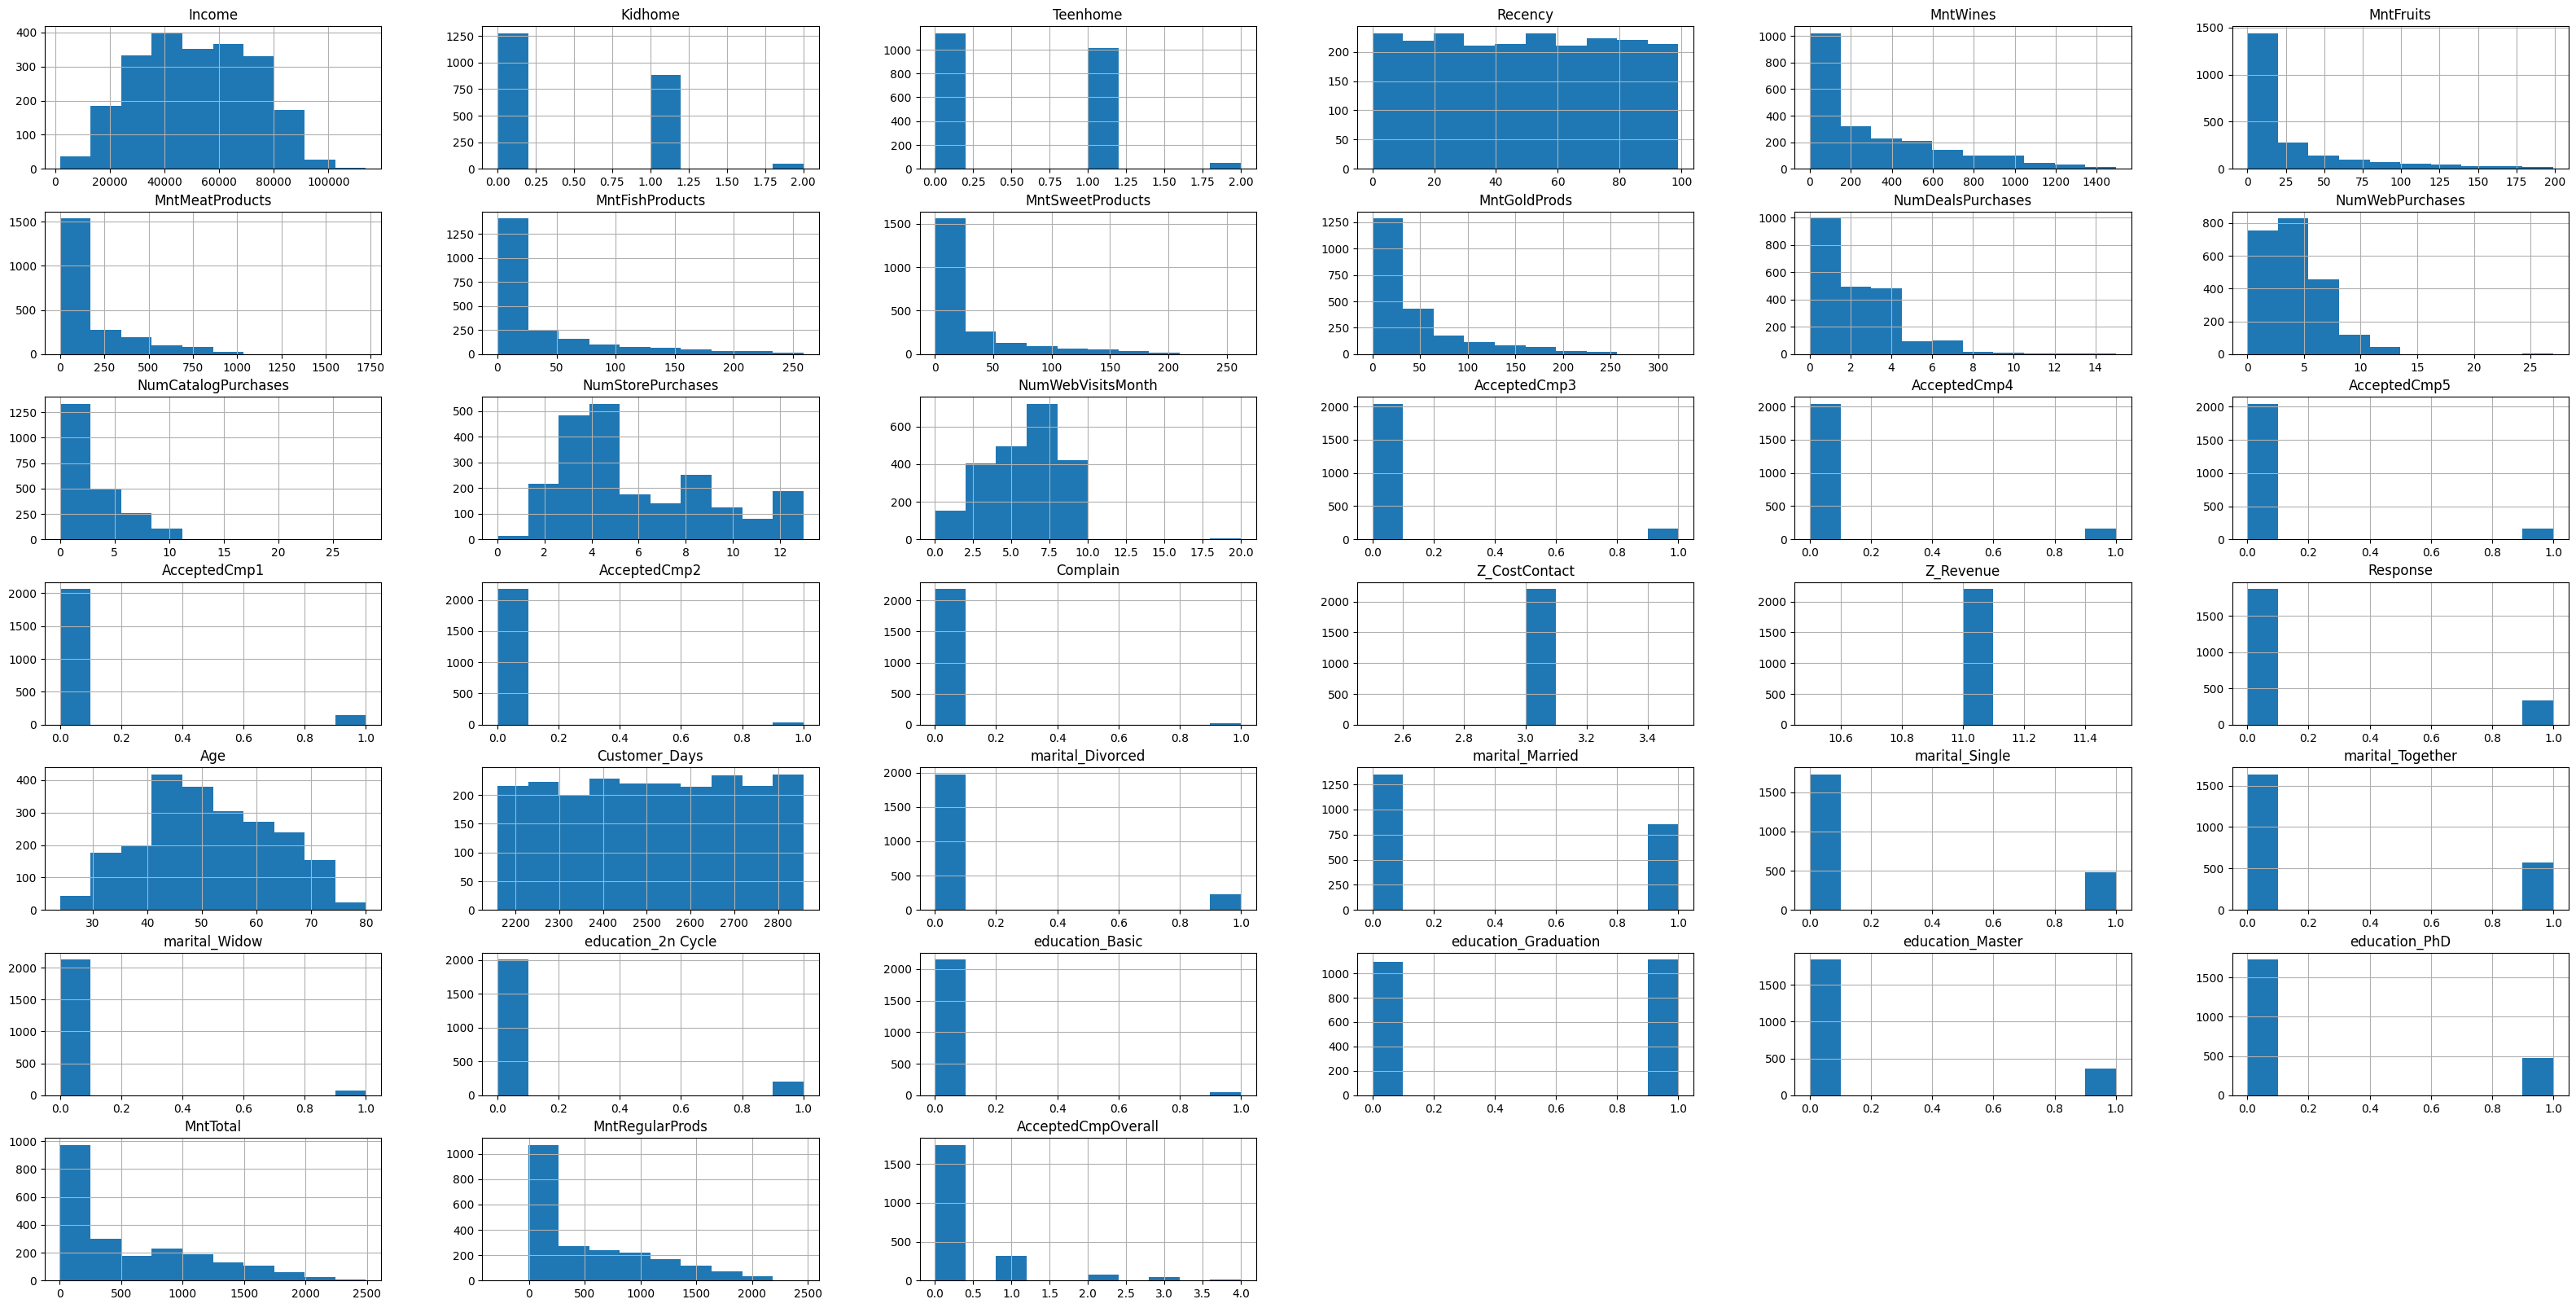

In [224]:
df.hist(figsize=(40,20))
plt.show()

In [225]:
df.sample(3)

,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,...,marital_Together,marital_Widow,education_2n Cycle,education_Basic,education_Graduation,education_Master,education_PhD,MntTotal,MntRegularProds,AcceptedCmpOverall
1228,20427.0,1,0,63,5,0,4,0,0,1,...,1,0,0,0,0,0,1,9,8,0
669,69476.0,0,0,3,260,86,559,63,9,67,...,1,0,0,0,0,0,1,977,910,0
681,71427.0,2,0,26,212,123,177,15,64,23,...,0,0,0,0,1,0,0,591,568,0


In [226]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2205 entries, 0 to 2204
Data columns (total 39 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Income                2205 non-null   float64
 1   Kidhome               2205 non-null   int64  
 2   Teenhome              2205 non-null   int64  
 3   Recency               2205 non-null   int64  
 4   MntWines              2205 non-null   int64  
 5   MntFruits             2205 non-null   int64  
 6   MntMeatProducts       2205 non-null   int64  
 7   MntFishProducts       2205 non-null   int64  
 8   MntSweetProducts      2205 non-null   int64  
 9   MntGoldProds          2205 non-null   int64  
 10  NumDealsPurchases     2205 non-null   int64  
 11  NumWebPurchases       2205 non-null   int64  
 12  NumCatalogPurchases   2205 non-null   int64  
 13  NumStorePurchases     2205 non-null   int64  
 14  NumWebVisitsMonth     2205 non-null   int64  
 15  AcceptedCmp3         

In [227]:
df.describe()

,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,...,marital_Together,marital_Widow,education_2n Cycle,education_Basic,education_Graduation,education_Master,education_PhD,MntTotal,MntRegularProds,AcceptedCmpOverall
count,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,...,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.00000
mean,51622.094785,0.442177,0.506576,49.009070,306.164626,26.403175,165.312018,37.756463,27.128345,44.057143,...,0.257596,0.034467,0.089796,0.024490,0.504762,0.165079,0.215873,562.764626,518.707483,0.29932
std,20713.063826,0.537132,0.544380,28.932111,337.493839,39.784484,217.784507,54.824635,41.130468,51.736211,...,0.437410,0.182467,0.285954,0.154599,0.500091,0.371336,0.411520,575.936911,553.847248,0.68044
min,1730.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000,-283.000000,0.00000
25%,35196.000000,0.000000,0.000000,24.000000,24.000000,2.000000,16.000000,3.000000,1.000000,9.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,56.000000,42.000000,0.00000
50%,51287.000000,0.000000,0.000000,49.000000,178.000000,8.000000,68.000000,12.000000,8.000000,25.000000,...,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,343.000000,288.000000,0.00000
75%,68281.000000,1.000000,1.000000,74.000000,507.000000,33.000000,232.000000,50.000000,34.000000,56.000000,...,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,964.000000,884.000000,0.00000
max,113734.000000,2.000000,2.000000,99.000000,1493.000000,199.000000,1725.000000,259.000000,262.000000,321.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2491.000000,2458.000000,4.00000


In [228]:
df.duplicated().sum()

np.int64(184)

In [229]:
df.head()

,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,...,marital_Together,marital_Widow,education_2n Cycle,education_Basic,education_Graduation,education_Master,education_PhD,MntTotal,MntRegularProds,AcceptedCmpOverall
0,58138.0,0,0,58,635,88,546,172,88,88,...,0,0,0,0,1,0,0,1529,1441,0
1,46344.0,1,1,38,11,1,6,2,1,6,...,0,0,0,0,1,0,0,21,15,0
2,71613.0,0,0,26,426,49,127,111,21,42,...,1,0,0,0,1,0,0,734,692,0
3,26646.0,1,0,26,11,4,20,10,3,5,...,1,0,0,0,1,0,0,48,43,0
4,58293.0,1,0,94,173,43,118,46,27,15,...,0,0,0,0,0,0,1,407,392,0


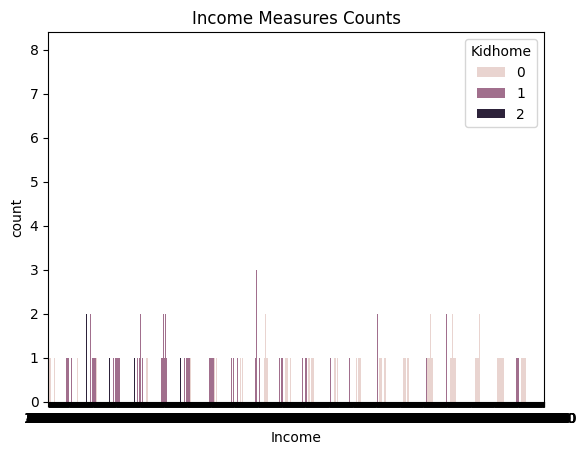

In [230]:
sns.countplot(x='Income' , hue='Kidhome',data=df)
plt.title('Income Measures Counts')
plt.show()

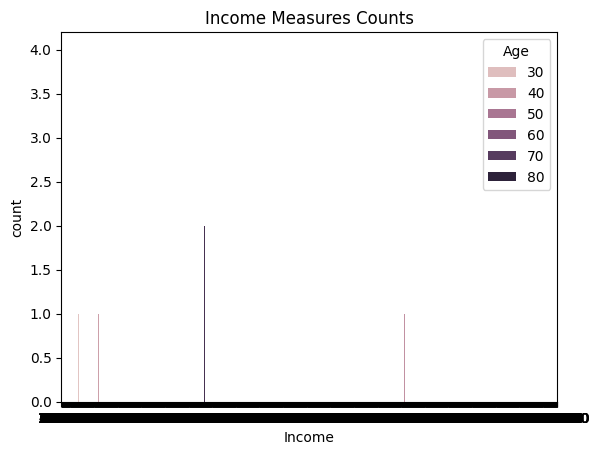

In [231]:
sns.countplot(x='Income' , hue='Age',data=df)
plt.title('Income Measures Counts')
plt.show()

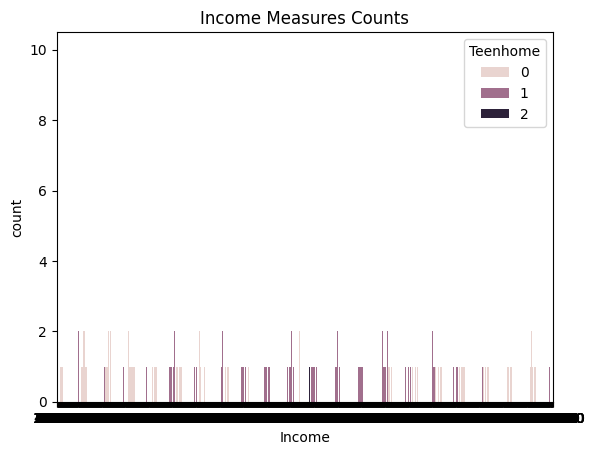

In [232]:
sns.countplot(x='Income' , hue='Teenhome',data=df)
plt.title('Income Measures Counts')
plt.show()

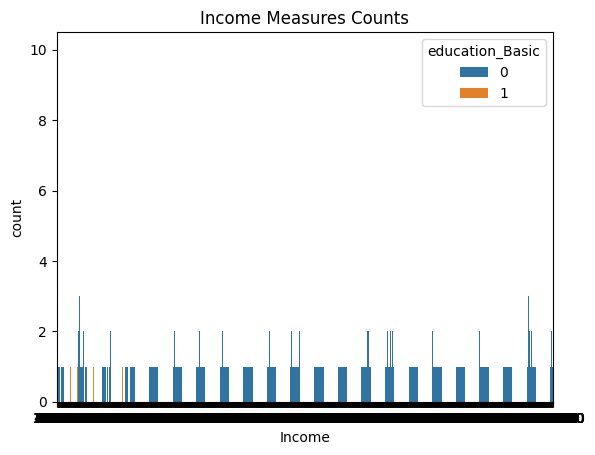

In [233]:
sns.countplot(x='Income' , hue='education_Basic',data=df)
plt.title('Income Measures Counts')
plt.show()

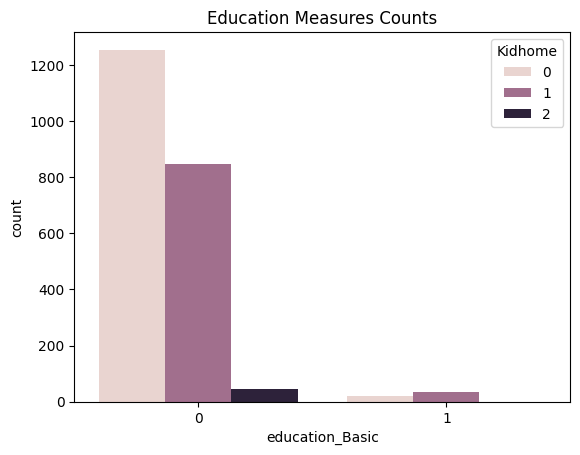

In [234]:
sns.countplot(x='education_Basic' , hue='Kidhome',data=df)
plt.title('Education Measures Counts')
plt.show()

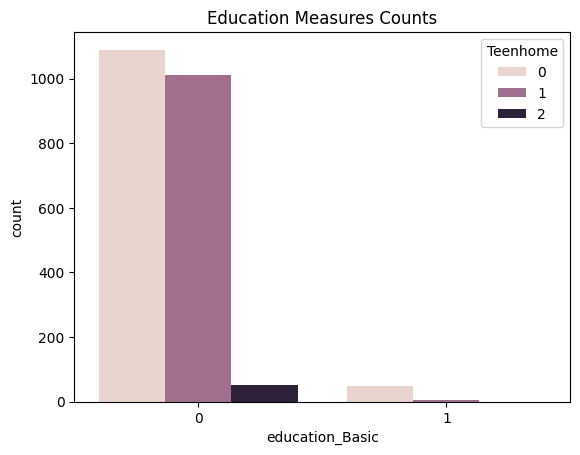

In [235]:
sns.countplot(x='education_Basic' , hue='Teenhome',data=df)
plt.title('Education Measures Counts')
plt.show()

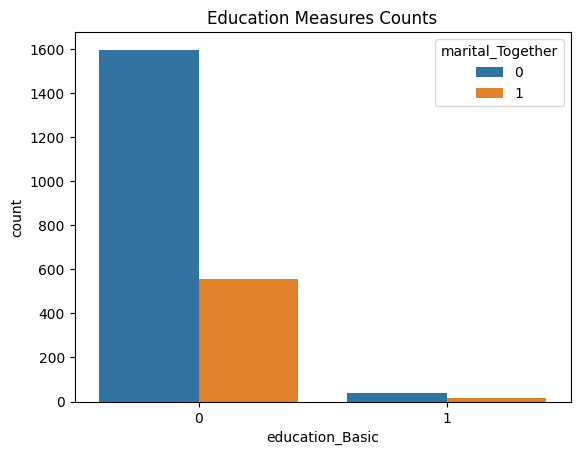

In [236]:
sns.countplot(x='education_Basic' , hue='marital_Together',data=df)
plt.title('Education Measures Counts')
plt.show()

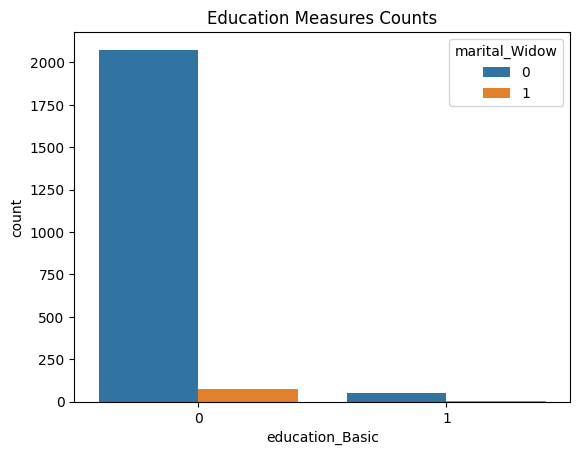

In [237]:
sns.countplot(x='education_Basic' , hue='marital_Widow',data=df)
plt.title('Education Measures Counts')
plt.show()

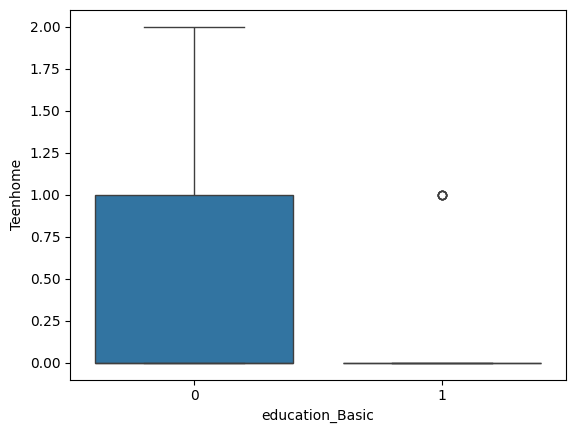

In [238]:
sns.boxplot(x=df['education_Basic'],y=df['Teenhome'])
plt.show()

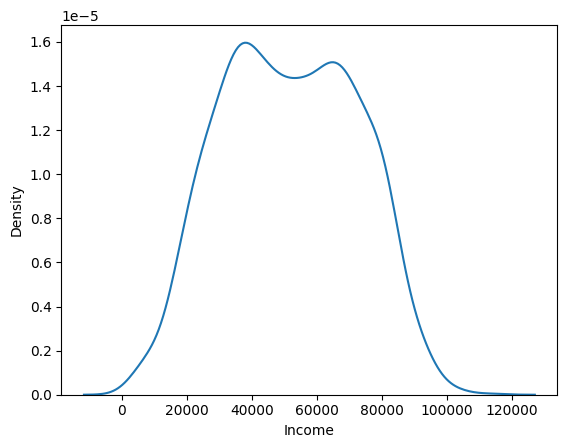

In [239]:
sns.kdeplot(df['Income'])
plt.show()

In [240]:
df.sample(1)

,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,...,marital_Together,marital_Widow,education_2n Cycle,education_Basic,education_Graduation,education_Master,education_PhD,MntTotal,MntRegularProds,AcceptedCmpOverall
473,78952.0,0,1,11,1170,19,594,99,76,134,...,1,0,0,0,0,0,1,1958,1824,0


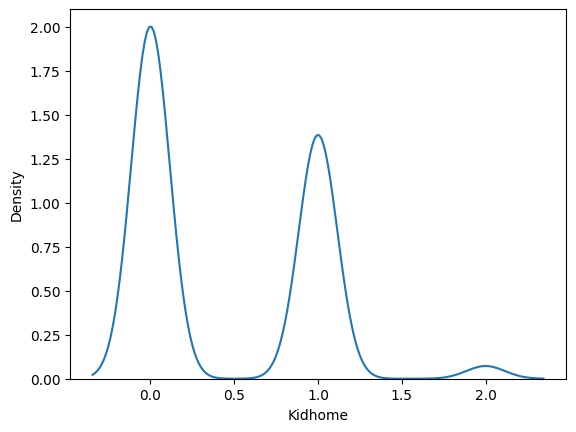

In [241]:
sns.kdeplot(df['Kidhome'])
plt.show()

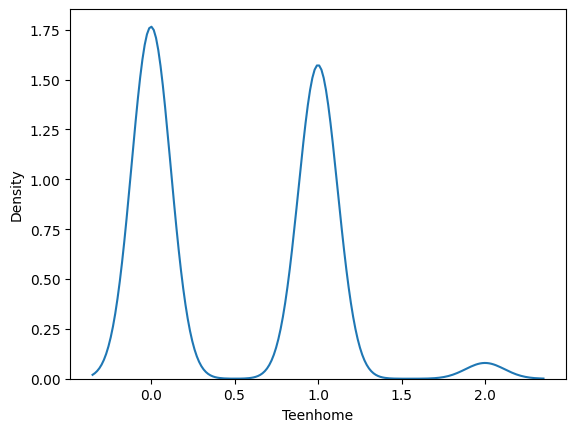

In [242]:
sns.kdeplot(df['Teenhome'])
plt.show()

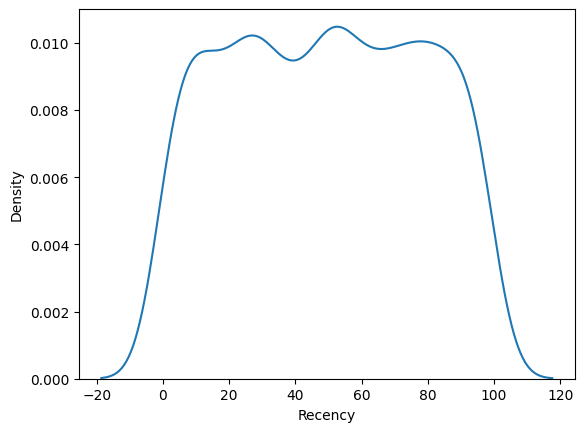

In [243]:
sns.kdeplot(df['Recency'])
plt.show()

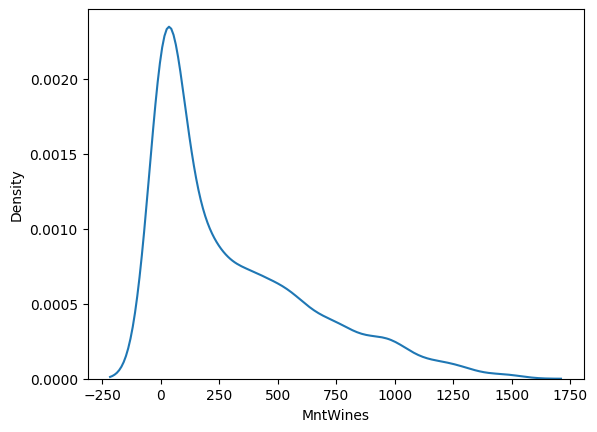

In [244]:
sns.kdeplot(df['MntWines'])
plt.show()

In [245]:
df.sample(1)

,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,...,marital_Together,marital_Widow,education_2n Cycle,education_Basic,education_Graduation,education_Master,education_PhD,MntTotal,MntRegularProds,AcceptedCmpOverall
629,55282.0,1,0,9,125,6,73,8,4,19,...,0,0,0,0,0,1,0,216,197,0


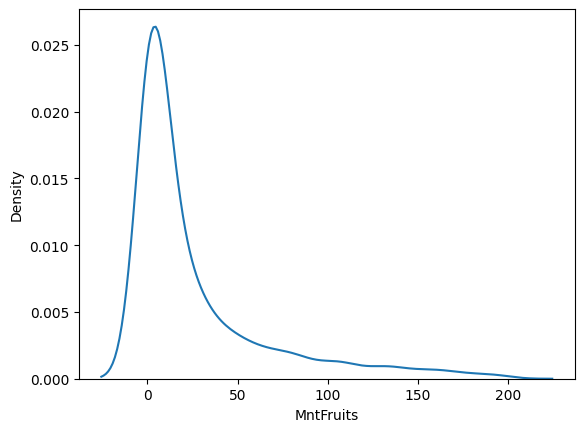

In [246]:
sns.kdeplot(df['MntFruits'])
plt.show()

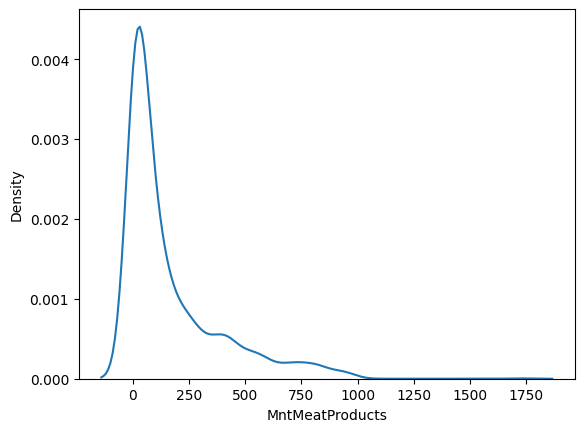

In [247]:
sns.kdeplot(df['MntMeatProducts'])
plt.show()

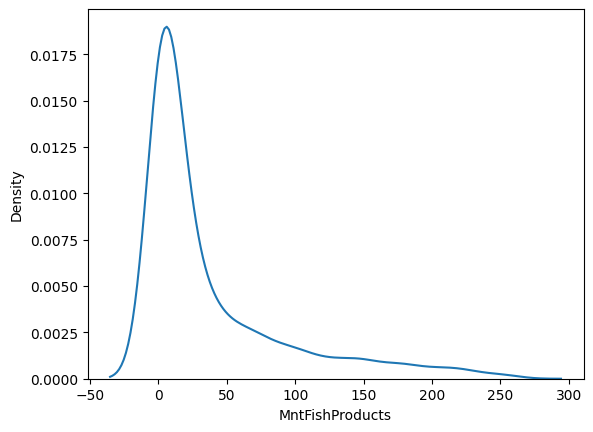

In [248]:
sns.kdeplot(df['MntFishProducts'])
plt.show()

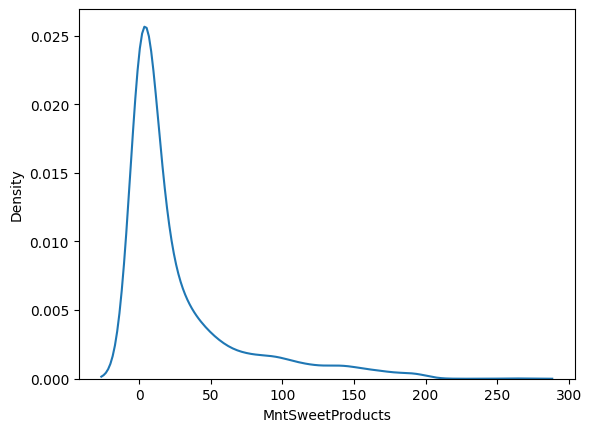

In [249]:
sns.kdeplot(df['MntSweetProducts'])
plt.show()

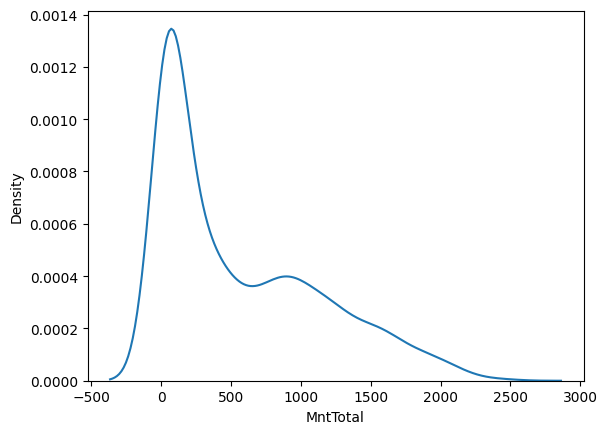

In [250]:
sns.kdeplot(df['MntTotal'])
plt.show()

In [251]:
df.duplicated().sum()

np.int64(184)

In [252]:
df.drop_duplicates(inplace=True)

In [253]:
df.duplicated().sum()

np.int64(0)

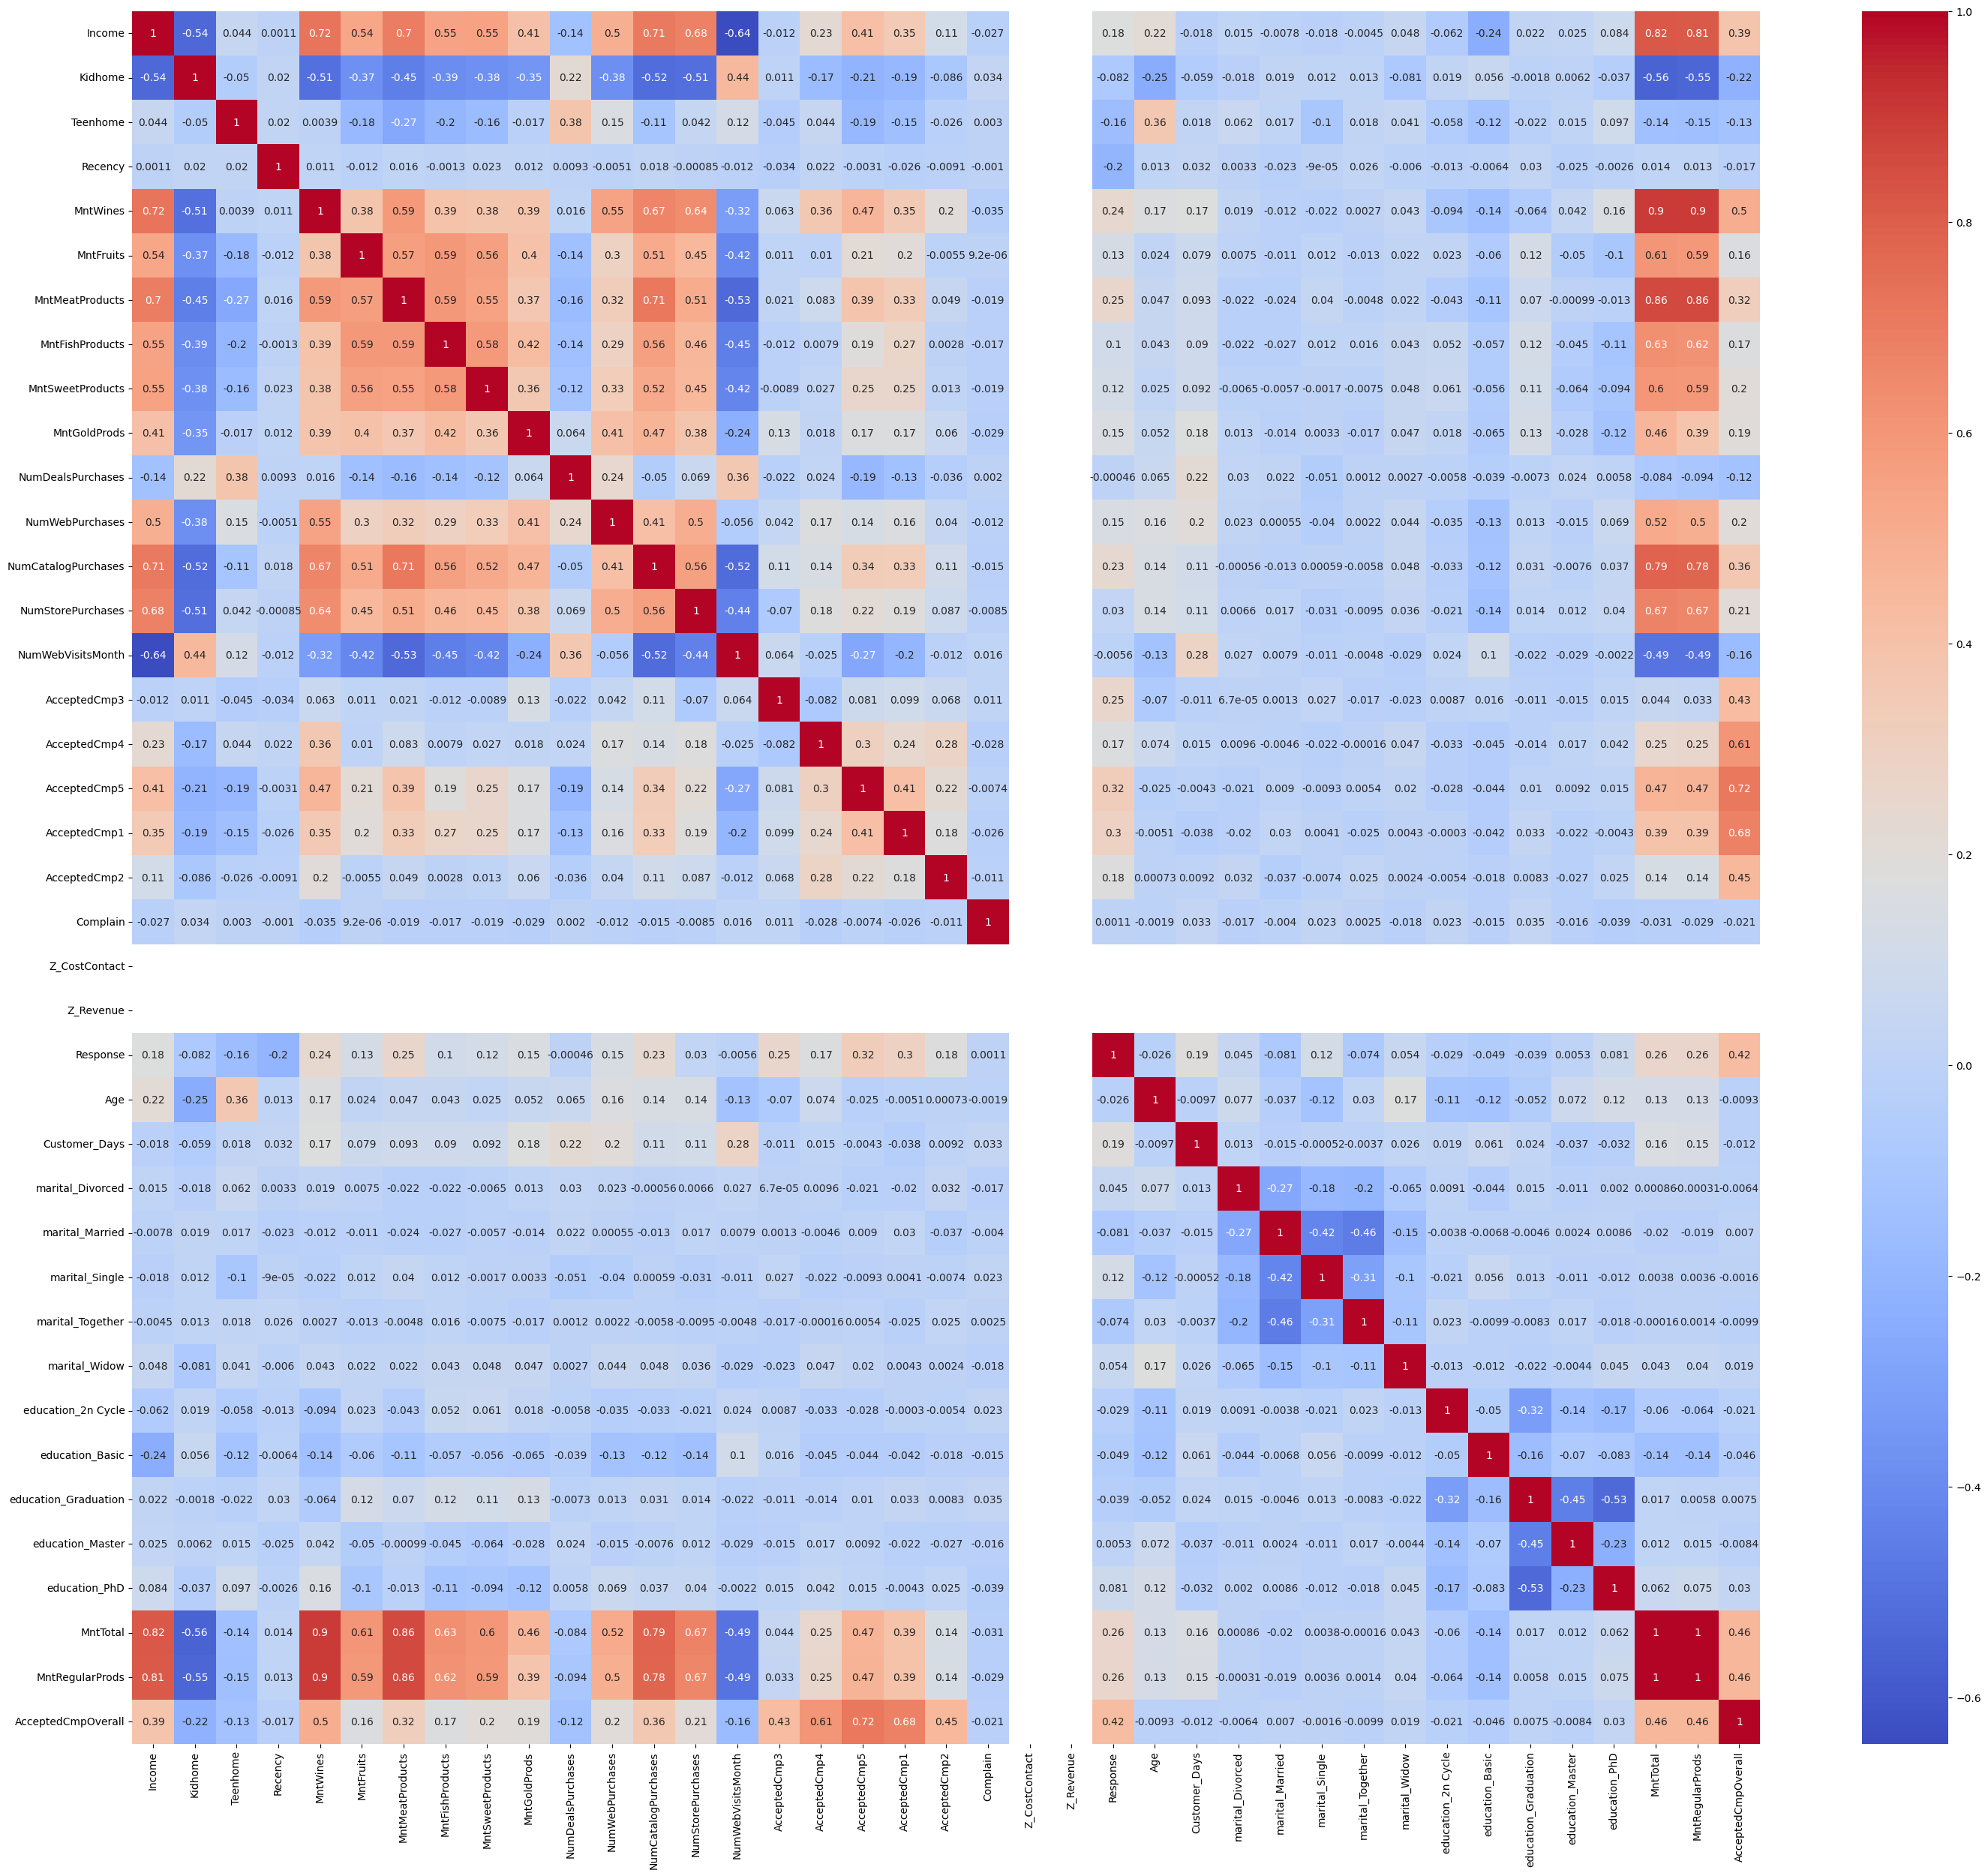

In [254]:
plt.figure(figsize=(35,30))
sns.heatmap(df.corr(numeric_only=True),annot=True,cmap='coolwarm')
plt.show()

In [255]:
df['Z_Revenue'].nunique()

1

In [256]:
df['Z_CostContact'].nunique()

1

In [257]:
df.drop

<bound method DataFrame.drop of        Income  Kidhome  Teenhome  Recency  MntWines  MntFruits  \
0     58138.0        0         0       58       635         88   
1     46344.0        1         1       38        11          1   
2     71613.0        0         0       26       426         49   
3     26646.0        1         0       26        11          4   
4     58293.0        1         0       94       173         43   
...       ...      ...       ...      ...       ...        ...   
2198  26816.0        0         0       50         5          1   
2200  61223.0        0         1       46       709         43   
2202  56981.0        0         0       91       908         48   
2203  69245.0        0         1        8       428         30   
2204  52869.0        1         1       40        84          3   

      MntMeatProducts  MntFishProducts  MntSweetProducts  MntGoldProds  ...  \
0                 546              172                88            88  ...   
1                   6                2                 1             6  ...   
2                 127              111                21            42  ...   
3                  20               10                 3             5  ...   
4                 118               46                27            15  ...   
...               ...              ...               ...           ...  ...   
2198                6                3                 4             3  ...   
2200              182               42               118           247  ...   
2202              217               32                12            24  ...   
2203              214               80                30            61  ...   
2204               61                2                 1            21  ...   

      marital_Together  marital_Widow  education_2n Cycle  education_Basic  \
0                    0              0                   0                0   
1                    0              0                   0                0   
2                    1              0                   0                0   
3                    1              0                   0                0   
4                    0              0                   0                0   
...                ...            ...                 ...              ...   
2198                 0              0                   0                0   
2200                 0              0                   0                0   
2202                 0              0                   0                0   
2203                 1              0                   0                0   
2204                 0              0                   0                0   

      education_Graduation  education_Master  education_PhD  MntTotal  \
0                        1                 0              0      1529   
1                        1                 0              0        21   
2                        1                 0              0       734   
3                        1                 0              0        48   
4                        0                 0              1       407   
...                    ...               ...            ...       ...   
2198                     1                 0              0        19   
2200                     1                 0              0      1094   
2202                     1                 0              0      1217   
2203                     0                 1              0       782   
2204                     0                 0              1       151   

      MntRegularProds  AcceptedCmpOverall  
0                1441                   0  
1                  15                   0  
2                 692                   0  
3                  43                   0  
4                 392                   0  
...               ...                 ...  
2198               16                   0  
2200              847                   0  
2202            

In [258]:
df = df.loc[:,df.nunique()>1]

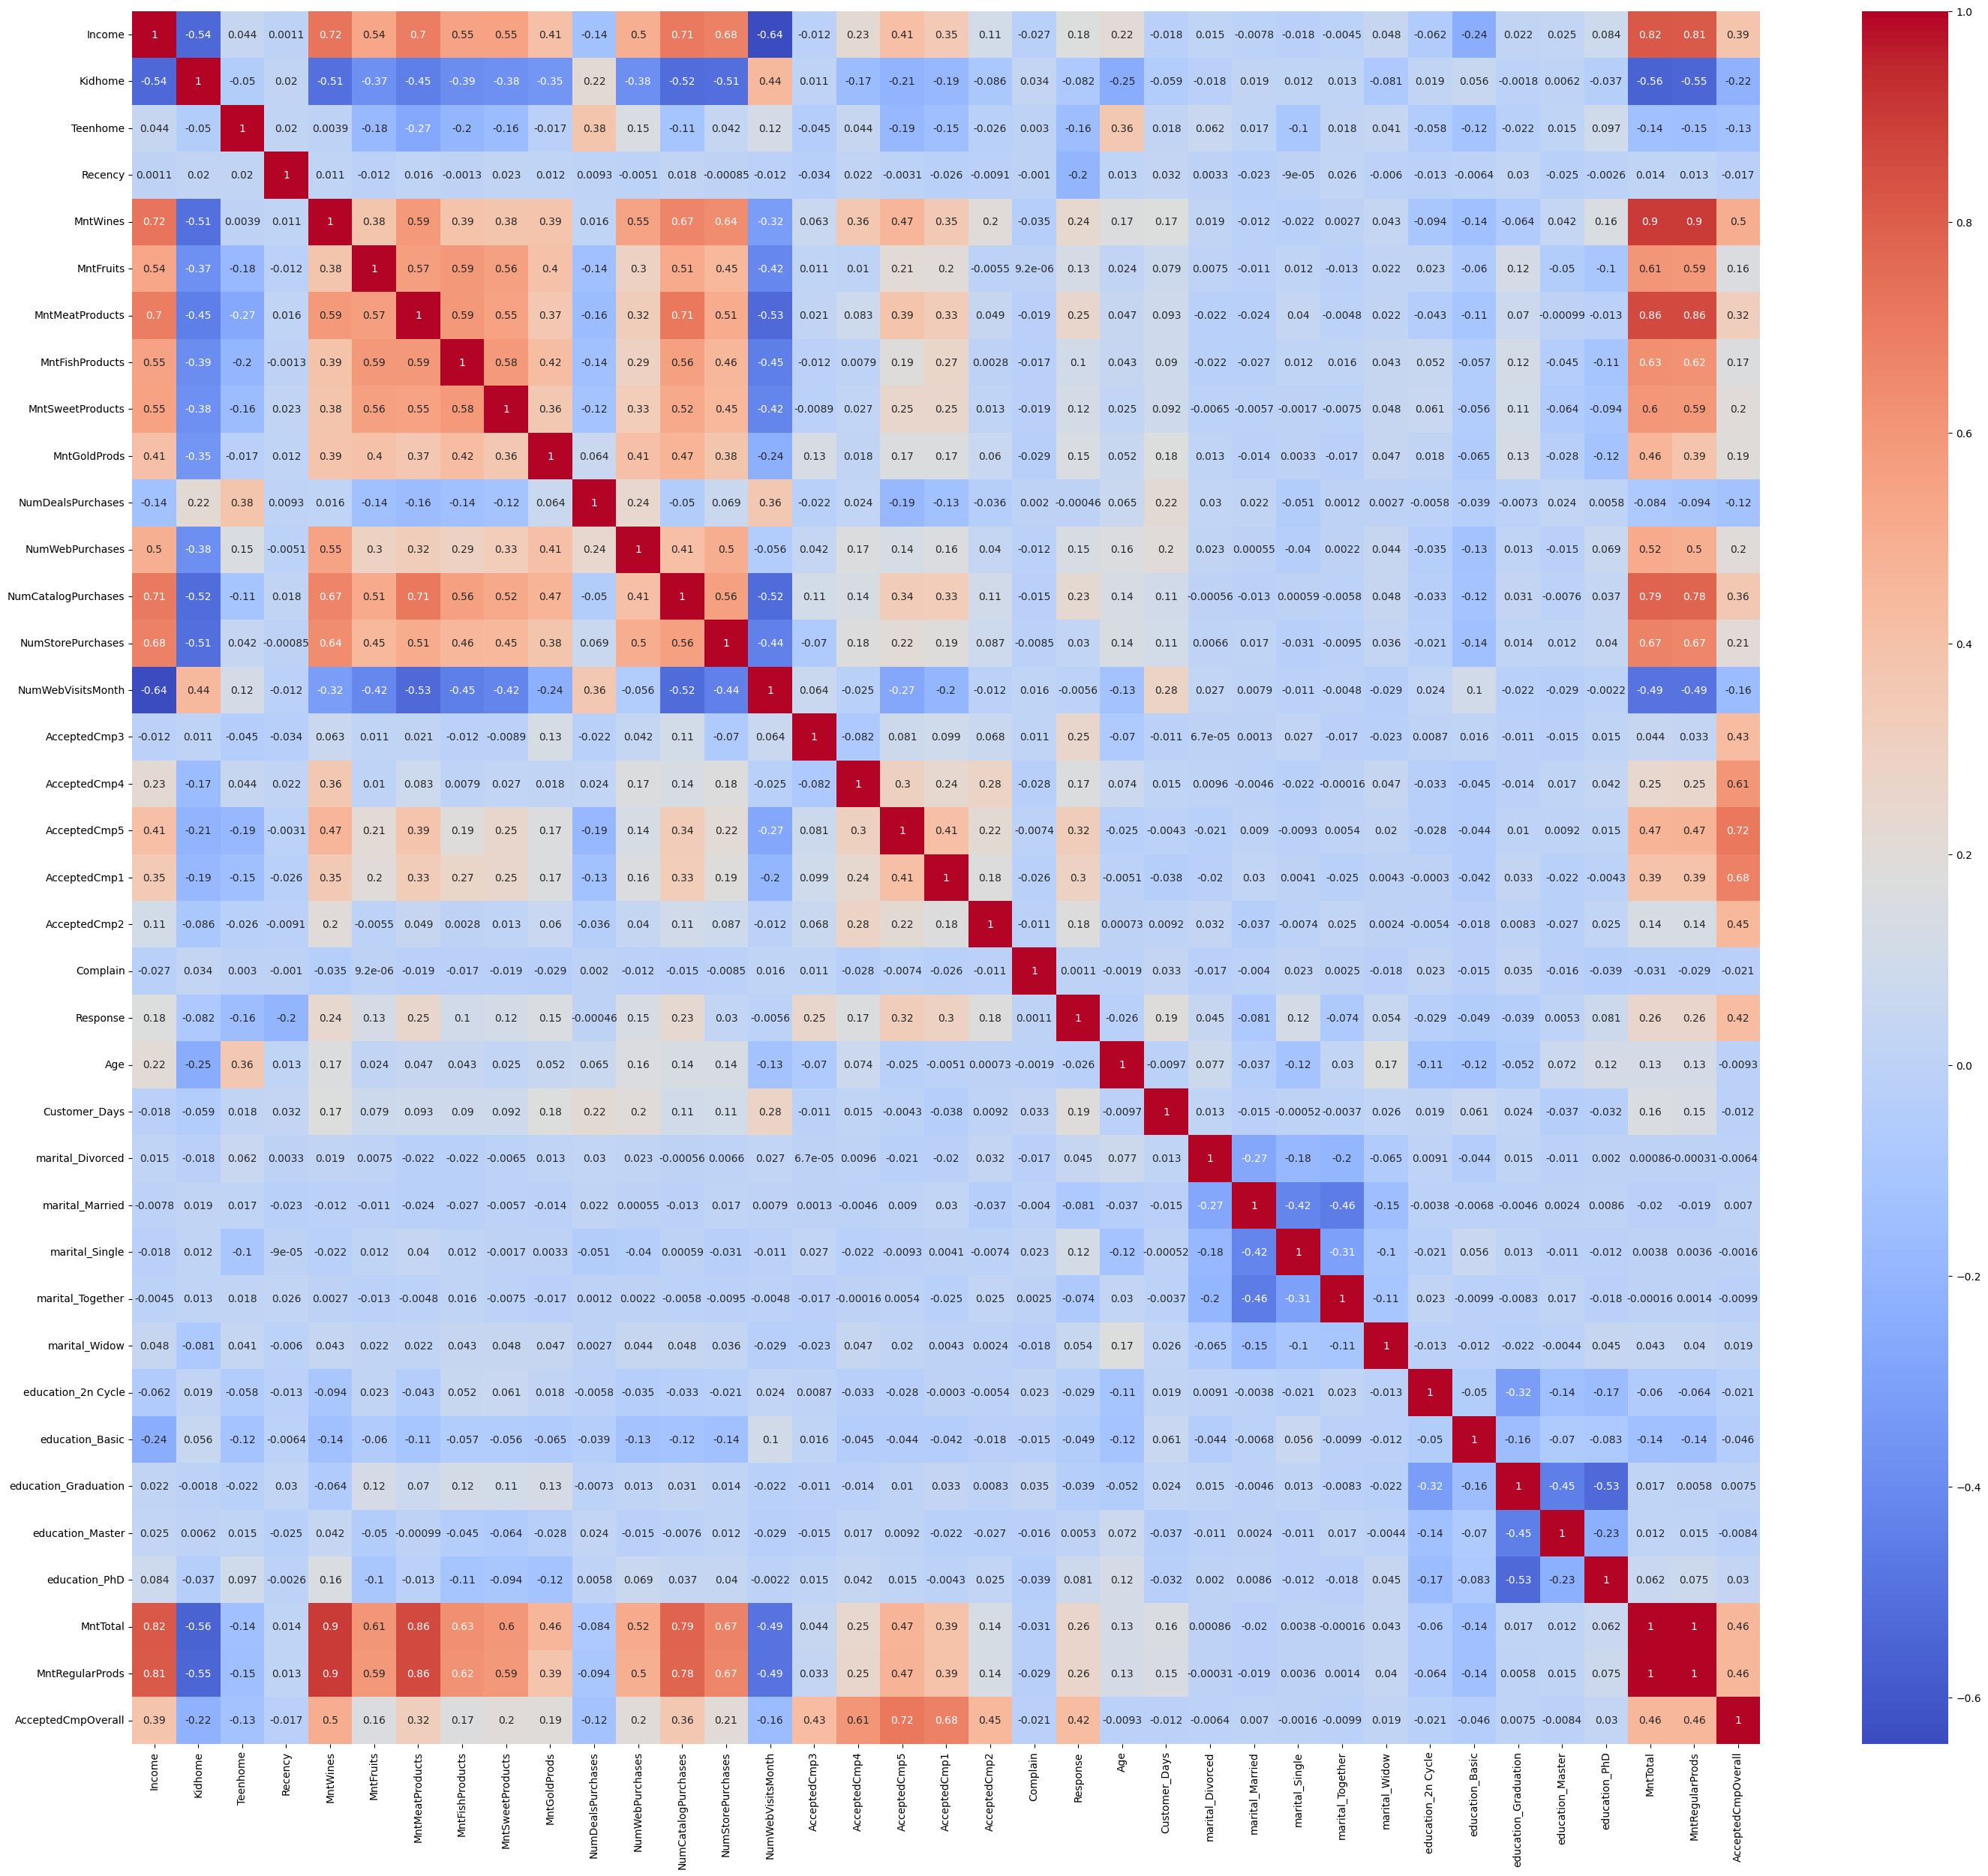

In [259]:
plt.figure(figsize=(35,30))
sns.heatmap(df.corr(numeric_only=True),annot=True,cmap='coolwarm')
plt.show()